In [15]:
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

colour1 = "royalblue"
colour2 = "red"


In [29]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Variables
DataSource = "Wind"
# Start  = "1995-01-01 00:00" # from T&C
Start  = "1996-01-01 00:00" # from SIDC
# End  = "2026-12-31 23:59"  # Up to most recent data (For Wind, not ICMECAT)
End = "1996-02-01 00:00"  # End of ICMECAT, after this we won't be able to remove the CMEs so stop the plotting here, EndOfCMECat

#Separated by data source as files may have different file name conventions
if DataSource == "Wind":
    YearlyRange = Yearly(Start, End, frequency = 'MS') # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = []
    StartAndEnd = []
    for i in range(len(YearlyRange)-1):
        StartDate = YearlyRange[i]
        EndDate = YearlyRange[i][0:6] + "31"
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound)
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS)
        StartAndEnd.append([StartDate, EndDate])

else:
    print("Data source not known")

['19960101', '19960201']


In [30]:
print(dataTimeSerieses)

SunPy TimeSeries
----------------
Observatory:			Unknown
Instrument:			Unknown
Channel(s):			Year<br>DOY<br>Hour<br>Minute<br>IMF_PTS<br>PercentInterp<br>CP/MVFlag<br>Timeshift<br>PFN_XGSE<br>PFN_YGSE<br>PFN_ZGSE<br>ScalarB<br>Bx_GSEGSM<br>ByGSE<br>BzGSE<br>ByGSM<br>BzGSM<br>RMSTimeshift<br>RMS_PFN<br>RMSScalarB<br>RMSFieldVector<br>Plasma_PTS<br>FlowSpeed<br>Vx_GSE<br>Vy_GSE<br>Vz_GSE<br>ProtonDensity<br>Temp<br>X_s_c_GSE<br>Y_s_c_GSE<br>Z_s_c_GSE<br>X_targ_GSE<br>Y_targ_GSE<br>Z_targ_GSE<br>RMS_targ<br>DBOT1<br>DBOT2<br>TotVsw
Start Date:			1996-01-01 00:00:00
End Date:			1996-01-31 23:59:00
Center Date:			1996-01-16 11:59:30
Resolution:			59.999 s
Samples per Channel:		44640
Data Range(s):		Year             0.00E+00<br>DOY              3.00E+01<br>Hour             2.30E+01<br>Minute           5.90E+01<br>IMF_PTS          7.80E+01<br>PercentInterp    1.00E+02<br>CP/MVFlag        1.00E+00<br>Timeshift        6.36E+03<br>PFN_XGSE         8.90E-01<br>PFN_YGSE         1.92E+00<br>PFN_ZGS

File not saved
DateTime
1996-01-01 00:00:00    False
1996-01-01 00:01:00    False
1996-01-01 00:02:00    False
1996-01-01 00:03:00    False
1996-01-01 00:04:00    False
                       ...  
1996-01-31 23:55:00    False
1996-01-31 23:56:00    False
1996-01-31 23:57:00    False
1996-01-31 23:58:00    False
1996-01-31 23:59:00    False
Name: TotVsw, Length: 44640, dtype: bool
Caption: Time series of solar wind speed with highlighted times that the values stay within the first (350-450km/s, royalblue)
 and second (550-650km/s, red) threshold. Highlighted sections are coloured coded to show each threshold.


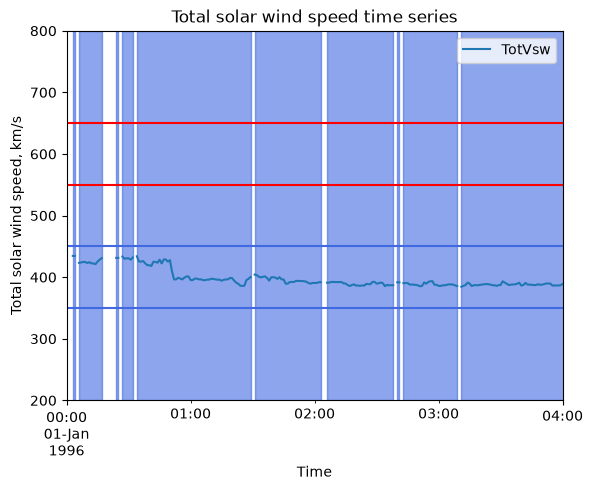

In [32]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-01 04:00"
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])

Alpha = 0.6

# FirstBaseValue = 400
# SecondBaseValue = 600
# AbsoluteThreshold = 50

# plt.hlines(FirstBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color="green")
# plt.hlines(FirstBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color="green")
# plt.hlines(SecondBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color="red")
# plt.hlines(SecondBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color="red")

# print(dataTimeSerieses[0].to_dataframe()["TotVsw"])

# mask = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(FirstBaseValue-AbsoluteThreshold, FirstBaseValue+AbsoluteThreshold)
# print(mask)

# # y = -1
# starts = []
# ends = []
# for x in range(len(mask)):
#     # y = y + 1
#     if mask.values[x] == True and mask.values[x-1] == False:
#         # print("Start")
#         starts.append(mask.index[x])
#     if mask.values[x] == True and mask.values[x-1] == True:
#         # print("Middle")
#         minor=0
#     if mask.values[x] == True and mask.values[x+1] == False:
#         # print("End")
#         ends.append(mask.index[x])
#     elif mask.values[x] == False:
#         minor=0
#         # print("Not in threshold")

# print(starts)
# print(ends)
# print(len(starts))
# print(len(ends))

#Multicoloured
# colors = ["red", "orange", "yellow", "green", "blue", "purple"]
# Colours = colors*(round(len(starts)/6))
# for y in range(len(starts)):
#     # print(y)
#     plt.axvspan(starts[y], ends[y], color = Colours[y], alpha = 0.1)

#Threshold 1
FirstBaseValue = 400
AbsoluteThreshold = 50

plt.hlines(FirstBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)
plt.hlines(FirstBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)

maskFirst = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(FirstBaseValue-AbsoluteThreshold, FirstBaseValue+AbsoluteThreshold)

# y = -1
starts = []
ends = []
for x in range(len(maskFirst)):
    # y = y + 1
    if maskFirst.values[x] == True and maskFirst.values[x-1] == False:
        # print("Start")
        starts.append(maskFirst.index[x])
    if maskFirst.values[x] == True and maskFirst.values[x-1] == True:
        # print("Middle")
        minor=0
    if maskFirst.values[x] == True and maskFirst.values[x+1] == False:
        # print("End")
        ends.append(maskFirst.index[x])
    elif maskFirst.values[x] == False:
        minor=0
        # print("Not in threshold")

for y in range(len(starts)):
    # print(y)
    # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)
    plt.axvspan(starts[y], ends[y], color = colour1, alpha = Alpha)



#Threshold 2
SecondBaseValue = 600
AbsoluteThreshold = 50

plt.hlines(SecondBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color= colour2)
plt.hlines(SecondBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color= colour2)

maskSecond = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(SecondBaseValue-AbsoluteThreshold, SecondBaseValue+AbsoluteThreshold)
print(maskSecond)

# y = -1
startsSecond = []
endsSecond = []
for x in range(len(maskSecond)):
    # y = y + 1
    if maskSecond.values[x] == True and maskSecond.values[x-1] == False:
        # print("Start")
        startsSecond.append(maskSecond.index[x])
    if maskSecond.values[x] == True and maskSecond.values[x-1] == True:
        # print("Middle")
        minor=0
    if maskSecond.values[x] == True and maskSecond.values[x+1] == False:
        # print("End")
        endsSecond.append(maskSecond.index[x])
    elif maskSecond.values[x] == False:
        minor=0
        # print("Not in threshold")

for y in range(len(startsSecond)):
    # print(y)
    # plt.axvspan(startsSecond[y], endsSecond[y], ymin = SecondBaseValue-AbsoluteThreshold, ymax = SecondBaseValue+AbsoluteThreshold, color = "red", alpha = 0.1)
    plt.axvspan(startsSecond[y], endsSecond[y], color = colour2, alpha = Alpha)


#General plot settings
plt.title("Total solar wind speed time series")
plt.xlabel("Time")
plt.ylabel("Total solar wind speed, km/s")
print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")

# for x in range(len(mask)):
#     if mask[x]


# InThreshold = dataTimeSerieses[0].to_dataframe()[mask]
# print(InThreshold)
# TimeSeries(InThreshold).plot(columns="TotVsw")
# PlotVsw(TimeSeries(InThreshold), Columns=["TotVsw"], XLim =["1996-01-01 00:00", "1996-01-08 00:00"], YLim = [200,800])
# dfOnlyCMEs = dataTimeSerieses[i].to_dataframe()[~MapForINDEX]

# for x in dataTimeSerieses[0].to_dataframe()["TotVsw"]:
#     if x > FirstBaseValue-AbsoluteThreshold and x < FirstBaseValue+AbsoluteThreshold:
#         if x-1 < FirstBaseValue-AbsoluteThreshold or x-1 > FirstBaseValue+AbsoluteThreshold:
#             print("dataTimeSerieses[0][" + str(x) + "] start of range")
#             plt.vlines(x, ymin = 200, ymax = 800, color="green")
#         if x+1 < FirstBaseValue-AbsoluteThreshold or x+1 > FirstBaseValue+AbsoluteThreshold:
#             print("dataTimeSerieses[0][" + str(x) + "] end of range")
#         else:
#             print("not at start or end")

Caption: Histogram of steadiness timeframes for TotVsw for the first (350-450km/s, royalblue) and second (550-650km/s, red) threshold.


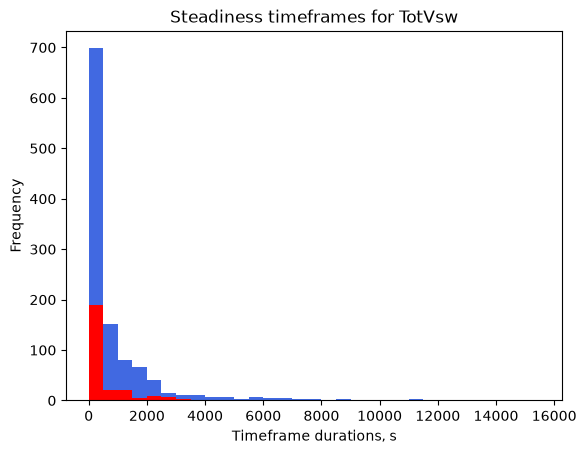

In [33]:
Bins = np.arange(0, 16000, 500)

#Threshold 1
tau1 = []
for x in range(len(starts)):
    tau1.append(ends[x]-starts[x])
# print(tau1)
tau1InSeconds = []
for y in range(len(tau1)):
    tau1InSeconds.append(tau1[y].total_seconds())
plt.hist(tau1InSeconds, bins = Bins, color= colour1)

#Threshold 2
tau2 = []
for x in range(len(startsSecond)):
    tau2.append(endsSecond[x]-startsSecond[x])
# print(tau2)
tau2InSeconds = []
for y in range(len(tau2)):
    tau2InSeconds.append(tau2[y].total_seconds())
plt.hist(tau2InSeconds, bins = Bins, color = colour2)

#General plot settings
plt.title("Steadiness timeframes for TotVsw")
plt.xlabel("Timeframe durations, s")
plt.ylabel("Frequency")
print("Caption: Histogram of steadiness timeframes for TotVsw for the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+") and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold.")


In [50]:
len(dataTimeSerieses[0].to_dataframe()["TotVsw"])
dataTimeSerieses[0].to_dataframe()["TotVsw"].values[10]

np.float64(423.0653495619796)

# New method

File not saved
This is the start.
Base value = nan, ThresMax = nan, ThresMin = nan


NameError: name 'start' is not defined

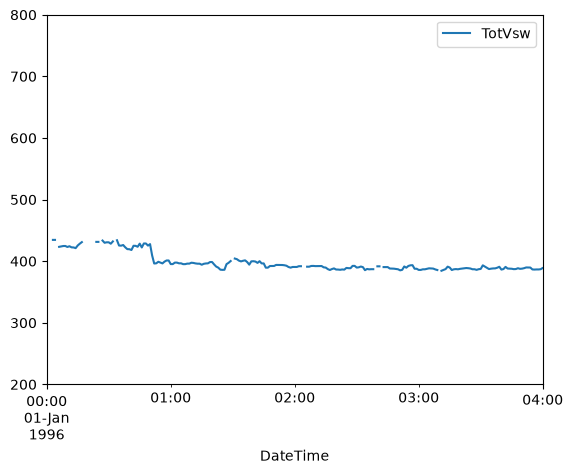

In [56]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-01 04:00"
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])

Alpha = 0.6

# FirstBaseValue = 400
# SecondBaseValue = 600
# AbsoluteThreshold = 50

# plt.hlines(FirstBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color="green")
# plt.hlines(FirstBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color="green")
# plt.hlines(SecondBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color="red")
# plt.hlines(SecondBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color="red")

# print(dataTimeSerieses[0].to_dataframe()["TotVsw"])

# mask = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(FirstBaseValue-AbsoluteThreshold, FirstBaseValue+AbsoluteThreshold)
# print(mask)

# # y = -1
# starts = []
# ends = []
# for x in range(len(mask)):
#     # y = y + 1
#     if mask.values[x] == True and mask.values[x-1] == False:
#         # print("Start")
#         starts.append(mask.index[x])
#     if mask.values[x] == True and mask.values[x-1] == True:
#         # print("Middle")
#         minor=0
#     if mask.values[x] == True and mask.values[x+1] == False:
#         # print("End")
#         ends.append(mask.index[x])
#     elif mask.values[x] == False:
#         minor=0
#         # print("Not in threshold")

# print(starts)
# print(ends)
# print(len(starts))
# print(len(ends))

#Multicoloured
# colors = ["red", "orange", "yellow", "green", "blue", "purple"]
# Colours = colors*(round(len(starts)/6))
# for y in range(len(starts)):
#     # print(y)
#     plt.axvspan(starts[y], ends[y], color = Colours[y], alpha = 0.1)

# start = np.nan
# en
for i in range(len(dataTimeSerieses[0].to_dataframe()["TotVsw"])):
    #Edgecase
    if i <100:
        print("This is the start.")
    if i == len(dataTimeSerieses[0].to_dataframe()["TotVsw"]):
        print("This is the end.")

    else:
        #Main case
        basevalue = dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i]
        thresMax = basevalue + (basevalue*0.5)
        thresMin = basevalue - (basevalue*0.5)
        print("Base value = " + str(basevalue) + ", ThresMax = " + str(thresMax)+ ", ThresMin = " + str(thresMin))

        for j in range(1,i):
            if dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i-j] >= thresMax or dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i-j] <= thresMin:
                print("Closest neighbour = " + str(j) + " away.")
                start = dataTimeSerieses[0].to_dataframe()["TotVsw"].index[i-j]
                j = i
            else:
                print("Still looking.")

        for k in range(1,i):
                if dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i+k] >= thresMax or dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i+k] <= thresMin:
                    print("Closest neighbour = " + str(k) + " away.")
                    end = dataTimeSerieses[0].to_dataframe()["TotVsw"].index[i+k]
                    k = i
                else:
                    print("Still looking.")
        plt.axvspan(start, end, color = colour1, alpha = Alpha)

plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)


# maskFirst = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(FirstBaseValue-AbsoluteThreshold, FirstBaseValue+AbsoluteThreshold)

# # y = -1
# starts = []
# ends = []
# for x in range(len(maskFirst)):
#     # y = y + 1
#     if maskFirst.values[x] == True and maskFirst.values[x-1] == False:
#         # print("Start")
#         starts.append(maskFirst.index[x])
#     if maskFirst.values[x] == True and maskFirst.values[x-1] == True:
#         # print("Middle")
#         minor=0
#     if maskFirst.values[x] == True and maskFirst.values[x+1] == False:
#         # print("End")
#         ends.append(maskFirst.index[x])
#     elif maskFirst.values[x] == False:
#         minor=0
#         # print("Not in threshold")

# for y in range(len(starts)):
#     # print(y)
#     # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)
#     plt.axvspan(starts[y], ends[y], color = colour1, alpha = Alpha)



# #Threshold 2
# SecondBaseValue = 600
# AbsoluteThreshold = 50

# plt.hlines(SecondBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color= colour2)
# plt.hlines(SecondBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color= colour2)

# maskSecond = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(SecondBaseValue-AbsoluteThreshold, SecondBaseValue+AbsoluteThreshold)
# print(maskSecond)

# # y = -1
# startsSecond = []
# endsSecond = []
# for x in range(len(maskSecond)):
#     # y = y + 1
#     if maskSecond.values[x] == True and maskSecond.values[x-1] == False:
#         # print("Start")
#         startsSecond.append(maskSecond.index[x])
#     if maskSecond.values[x] == True and maskSecond.values[x-1] == True:
#         # print("Middle")
#         minor=0
#     if maskSecond.values[x] == True and maskSecond.values[x+1] == False:
#         # print("End")
#         endsSecond.append(maskSecond.index[x])
#     elif maskSecond.values[x] == False:
#         minor=0
#         # print("Not in threshold")

# for y in range(len(startsSecond)):
#     # print(y)
#     # plt.axvspan(startsSecond[y], endsSecond[y], ymin = SecondBaseValue-AbsoluteThreshold, ymax = SecondBaseValue+AbsoluteThreshold, color = "red", alpha = 0.1)
#     plt.axvspan(startsSecond[y], endsSecond[y], color = colour2, alpha = Alpha)


#General plot settings
plt.title("Total solar wind speed time series")
plt.xlabel("Time")
plt.ylabel("Total solar wind speed, km/s")
print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")

# for x in range(len(mask)):
#     if mask[x]


# InThreshold = dataTimeSerieses[0].to_dataframe()[mask]
# print(InThreshold)
# TimeSeries(InThreshold).plot(columns="TotVsw")
# PlotVsw(TimeSeries(InThreshold), Columns=["TotVsw"], XLim =["1996-01-01 00:00", "1996-01-08 00:00"], YLim = [200,800])
# dfOnlyCMEs = dataTimeSerieses[i].to_dataframe()[~MapForINDEX]

# for x in dataTimeSerieses[0].to_dataframe()["TotVsw"]:
#     if x > FirstBaseValue-AbsoluteThreshold and x < FirstBaseValue+AbsoluteThreshold:
#         if x-1 < FirstBaseValue-AbsoluteThreshold or x-1 > FirstBaseValue+AbsoluteThreshold:
#             print("dataTimeSerieses[0][" + str(x) + "] start of range")
#             plt.vlines(x, ymin = 200, ymax = 800, color="green")
#         if x+1 < FirstBaseValue-AbsoluteThreshold or x+1 > FirstBaseValue+AbsoluteThreshold:
#             print("dataTimeSerieses[0][" + str(x) + "] end of range")
#         else:
#             print("not at start or end")